# Fit Tantalum Hugoniot

Needed to redo the impedance match solution for the {cite:t}`Lyzenga1983` data.


In [2]:
#@title Double-click to collapse code

# required python modules
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
#import panel as pn
#pn.extension('tabulator')
import os
from os.path import exists
import IM_module as IM # load classes and functions required for this impedance match notebook


In [3]:
ta = IM.Material()
ta.ihed.id = 75

In [4]:
ta.GetIHED(upmin=0.,upmax=1.e99,uselocalbool=True)

(array([3.13282037e-05, 1.18088701e+00, 3.40464333e+03]), array([[ 1.08450186e-10, -4.57750187e-07,  4.00194273e-04],
       [-4.57750187e-07,  2.02945196e-03, -1.88392158e+00],
       [ 4.00194273e-04, -1.88392158e+00,  1.93956201e+03]]))
[3.13282037e-05 1.18088701e+00 3.40464333e+03]


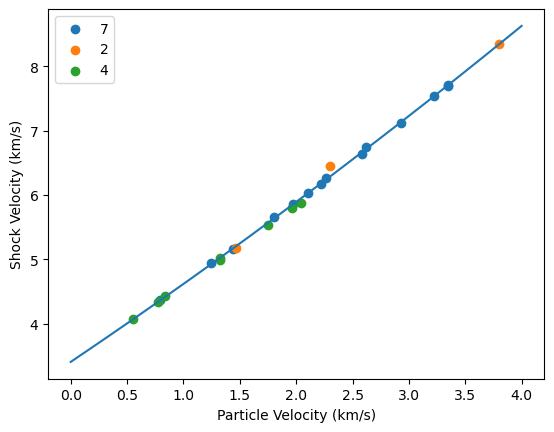

In [5]:
ind = np.where( (ta.ihed.uparr > 500) & (ta.ihed.uparr < 5000) & (ta.ihed.marr == 1.0))[0]
nrefs = np.unique(ta.ihed.refid[ind])
fitup = []
fitus = []
for iref in [7,2,4]:
#for iref in nrefs:
    iind = np.where( (ta.ihed.uparr > 500) & (ta.ihed.uparr < 6000) & (ta.ihed.marr == 1.0) & (ta.ihed.refid == iref) )[0]
    if iref == 4:
        iind = np.where( (ta.ihed.uparr > 500) & (ta.ihed.uparr < 2100) & (ta.ihed.marr == 1.0) & (ta.ihed.refid == iref) )[0]
    fitup = np.append(fitup,ta.ihed.uparr[iind])
    fitus = np.append(fitus,ta.ihed.usarr[iind])
    plt.scatter(ta.ihed.uparr[iind]/1.e3,ta.ihed.usarr[iind]/1.e3,label=str(iref))
#plt.scatter(fitup,fitus)

fitparams = np.polyfit(fitup,fitus,2,cov=True) # mks
print(fitparams)
coefs = fitparams[0]
print(coefs)
uparr = np.arange(4000)
plt.plot(uparr/1.e3,(coefs[2]+uparr*coefs[1]+uparr*uparr*coefs[0])/1.e3)
plt.xlabel('Particle Velocity (km/s)')
plt.ylabel('Shock Velocity (km/s)')
plt.legend()


(array([1.31311814e+00, 3.28903847e+03]), array([[ 1.31441527e-04, -2.62935631e-01],
       [-2.62935631e-01,  6.24772442e+02]]))
[1.31311814e+00 3.28903847e+03]
[[ 1.31441527e-04 -2.62935631e-01]
 [-2.62935631e-01  6.24772442e+02]]


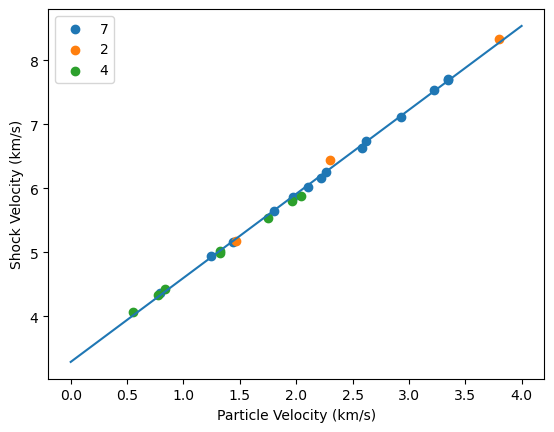

In [6]:
ind = np.where( (ta.ihed.uparr > 500) & (ta.ihed.uparr < 5000) & (ta.ihed.marr == 1.0))[0]
nrefs = np.unique(ta.ihed.refid[ind])
fitup = []
fitus = []
for iref in [7,2,4]:
#for iref in nrefs:
    iind = np.where( (ta.ihed.uparr > 500) & (ta.ihed.uparr < 6000) & (ta.ihed.marr == 1.0) & (ta.ihed.refid == iref) )[0]
    if iref == 4:
        iind = np.where( (ta.ihed.uparr > 500) & (ta.ihed.uparr < 2100) & (ta.ihed.marr == 1.0) & (ta.ihed.refid == iref) )[0]
    fitup = np.append(fitup,ta.ihed.uparr[iind])
    fitus = np.append(fitus,ta.ihed.usarr[iind])
    plt.scatter(ta.ihed.uparr[iind]/1.e3,ta.ihed.usarr[iind]/1.e3,label=str(iref))
#plt.scatter(fitup,fitus)

fitparams = np.polyfit(fitup,fitus,1,cov=True) # mks
print(fitparams)
coefs = fitparams[0]
print(coefs)
print(fitparams[1])
uparr = np.arange(4000)
plt.plot(uparr/1.e3,(coefs[1]+uparr*coefs[0])/1.e3)
plt.xlabel('Particle Velocity (km/s)')
plt.ylabel('Shock Velocity (km/s)')
plt.legend()
